# Validación mes por mes

¿El modelo es estable de un mes a otro, y en qué meses falla? Cada mes calendario completo (de `DESDE` en adelante)
es una ventana de prueba y **entrena con todos los días anteriores** (walk-forward, sin mezclar el tiempo).

- Solo XGBoost de la versión 1 (`02_modelo.ipynb`) con **los mismos hiperparámetros**, sin búsqueda nueva ni MLP.
  El número de árboles se elige por early stopping dentro de cada train.
- Se compara contra el promedio histórico y la media de 4 semanas.
- No usa calendario ni clima: el clima descargado y el calendario SEP cubren solo mar–ago 2026.
- Con solo los CSV de mar–ago 2026, los meses evaluables son mayo a agosto (abril tendría 3 semanas de entrenamiento).
  Si la computadora tiene también sep 2025 – feb 2026 (como el notebook 05), se detecta solo y se evalúan marzo a agosto.

**Cómo correrlo:** Restart & Run All. Necesita `trips_clean.parquet` y `data/processed/busqueda_hiperparametros.csv`.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import modelo as M

DESDE = "2026-03-01"          # primer mes que se evalúa (si hay historia suficiente)
MIN_DIAS_TRAIN = 42           # mínimo de días de entrenamiento antes de un mes de prueba
COMPARAR_6M = False            # además, entrenar solo con los ~6 meses previos (se omite si no cambia nada)

# ¿Hay datos de antes de marzo 2026 (sep 2025 – feb 2026)? Si sí, se usan para entrenar los primeros meses.
fechas_viajes = pd.read_parquet(f"{M.PROCESSED_DIR}/trips_clean.parquet", columns=["origen_dt"])["origen_dt"]
previos = ((fechas_viajes >= "2025-09-01") & (fechas_viajes < "2026-03-01")).sum()
M.FECHA_INICIO = "2025-09-01" if previos > 1_000_000 else "2026-03-01"
M.FECHA_FIN = "2026-09-30"   # este notebook sí incluye septiembre 2026 (modelo.py corta en agosto por defecto)
del fechas_viajes
print(f"Viajes de sep 2025 – feb 2026 en el parquet: {previos:,} -> historia desde {M.FECHA_INICIO}")

Viajes de sep 2025 – feb 2026 en el parquet: 9,440,651 -> historia desde 2025-09-01


In [2]:
validos = M.cargar_validos()
estaciones = M.cargar_estaciones()
tabla = M.construir_tabla(validos, estaciones)
print(f"Filas: {len(tabla):,} | {tabla['fecha'].min().date()} a {tabla['fecha'].max().date()}")

h = pd.read_csv("../data/processed/busqueda_hiperparametros.csv").iloc[0]
params = {k: (h[k] if k == "objective" else int(h[k]) if k in ("max_depth", "min_child_weight") else float(h[k]))
          for k in M.ESPACIO_BUSQUEDA}
print("Hiperparámetros (versión 1):", params)

Filas: 6,276,696 | 2025-09-10 a 2026-09-30
Hiperparámetros (versión 1): {'learning_rate': 0.1, 'max_depth': 8, 'subsample': 1.0, 'colsample_bytree': 0.8, 'min_child_weight': 20, 'objective': 'count:poisson'}


## Entrenamiento y evaluación mes por mes

In [3]:
filas = []
for train, test, ini, fin in M.ventanas_mensuales(tabla, desde=DESDE, min_dias_train=MIN_DIAS_TRAIN):
    mes = f"{ini:%Y-%m}"
    y = test[M.TARGET].to_numpy()
    preds = {
        "Promedio histórico": M.baseline_promedio(train, test),
        "Media 4 semanas": M.baseline_media_4sem(test),
    }
    n_arb = M.elegir_arboles(train, params)
    preds["XGBoost (todo lo anterior)"] = np.clip(M.entrenar_xgb(train, params, n_arb).predict(test[M.FEATURES]), 0, None)

    if COMPARAR_6M:
        train6 = train[train["fecha"] >= ini - pd.Timedelta(days=182)]
        if len(train6) < len(train):          # solo tiene sentido si realmente recorta algo
            n6 = M.elegir_arboles(train6, params)
            preds["XGBoost (últimos 6 meses)"] = np.clip(M.entrenar_xgb(train6, params, n6).predict(test[M.FEATURES]), 0, None)

    for nombre, p in preds.items():
        filas.append({"mes": mes, "modelo": nombre, "dias_train": train["fecha"].nunique(),
                      "demanda_prueba": float(y.mean()), "demanda_train": float(train[M.TARGET].mean()),
                      **M.metricas(y, p)})
    print(mes, f"| train {train['fecha'].nunique()} días | demanda prueba {y.mean():.2f} (train {train[M.TARGET].mean():.2f}) | "
          + " | ".join(f"{k}: {M.metricas(y, v)['RMSE']:.3f}" for k, v in preds.items()))

res = pd.DataFrame(filas)
res.round(4).to_csv("../data/processed/resultados_mensual.csv", index=False)

2026-03 | train 172 días | demanda prueba 3.22 (train 3.15) | Promedio histórico: 2.573 | Media 4 semanas: 2.654 | XGBoost (todo lo anterior): 2.464
2026-04 | train 203 días | demanda prueba 3.21 (train 3.16) | Promedio histórico: 2.539 | Media 4 semanas: 2.654 | XGBoost (todo lo anterior): 2.478
2026-05 | train 233 días | demanda prueba 3.15 (train 3.17) | Promedio histórico: 2.565 | Media 4 semanas: 2.585 | XGBoost (todo lo anterior): 2.473
2026-06 | train 264 días | demanda prueba 3.00 (train 3.16) | Promedio histórico: 2.715 | Media 4 semanas: 2.797 | XGBoost (todo lo anterior): 2.621
2026-07 | train 294 días | demanda prueba 2.92 (train 3.15) | Promedio histórico: 2.538 | Media 4 semanas: 2.556 | XGBoost (todo lo anterior): 2.383
2026-08 | train 325 días | demanda prueba 2.88 (train 3.12) | Promedio histórico: 2.604 | Media 4 semanas: 2.477 | XGBoost (todo lo anterior): 2.371
2026-09 | train 356 días | demanda prueba 3.03 (train 3.10) | Promedio histórico: 2.622 | Media 4 semanas:

## Resultados por mes

In [4]:
for metrica in ["RMSE", "MAE", "Sesgo"]:
    t = res.pivot(index="modelo", columns="mes", values=metrica)
    t["Promedio"] = t.mean(axis=1)
    display(t.sort_values("Promedio").round(3).style.set_caption(metrica))

mes,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,Promedio
modelo,,,,,,,,
XGBoost (todo lo anterior),2.464000,2.478000,2.473000,2.621000,2.383000,2.371000,2.539000,2.475000
Promedio histórico,2.573000,2.539000,2.565000,2.715000,2.538000,2.604000,2.622000,2.594000
Media 4 semanas,2.654000,2.654000,2.585000,2.797000,2.556000,2.477000,2.685000,2.630000


mes,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,Promedio
modelo,,,,,,,,
XGBoost (todo lo anterior),1.429000,1.466000,1.455000,1.533000,1.392000,1.371000,1.465000,1.444000
Promedio histórico,1.472000,1.488000,1.504000,1.581000,1.473000,1.461000,1.507000,1.498000
Media 4 semanas,1.520000,1.561000,1.528000,1.626000,1.485000,1.437000,1.543000,1.529000


mes,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,Promedio
modelo,,,,,,,,
Media 4 semanas,0.061000,-0.072000,0.034000,0.230000,-0.003000,-0.032000,-0.054000,0.024000
XGBoost (todo lo anterior),-0.026000,-0.061000,0.006000,0.210000,0.114000,0.070000,0.025000,0.048000
Promedio histórico,-0.081000,-0.024000,-0.034000,0.188000,0.272000,0.202000,0.108000,0.090000


In [5]:
# Mejora de RMSE contra el promedio histórico, por mes (%), y demanda media de cada mes de prueba
t = res.pivot(index="modelo", columns="mes", values="RMSE")
mejora = (1 - t / t.loc["Promedio histórico"]) * 100
mejora["Promedio"] = mejora.mean(axis=1)
dem = res.drop_duplicates("mes").set_index("mes")[["demanda_prueba", "demanda_train", "dias_train"]]
display(mejora.sort_values("Promedio", ascending=False).round(1).style.set_caption("Mejora de RMSE vs promedio histórico (%)"))
display(dem.round(2).T.style.set_caption("Demanda media (salidas por estación-hora) y días de entrenamiento"))

mes,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,Promedio
modelo,,,,,,,,
XGBoost (todo lo anterior),4.200000,2.400000,3.600000,3.500000,6.100000,8.900000,3.200000,4.600000
Promedio histórico,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Media 4 semanas,-3.100000,-4.600000,-0.800000,-3.000000,-0.700000,4.900000,-2.400000,-1.400000


mes,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
demanda_prueba,3.220000,3.210000,3.150000,3.000000,2.920000,2.880000,3.030000
demanda_train,3.150000,3.160000,3.170000,3.160000,3.150000,3.120000,3.100000
dias_train,172.000000,203.000000,233.000000,264.000000,294.000000,325.000000,356.000000


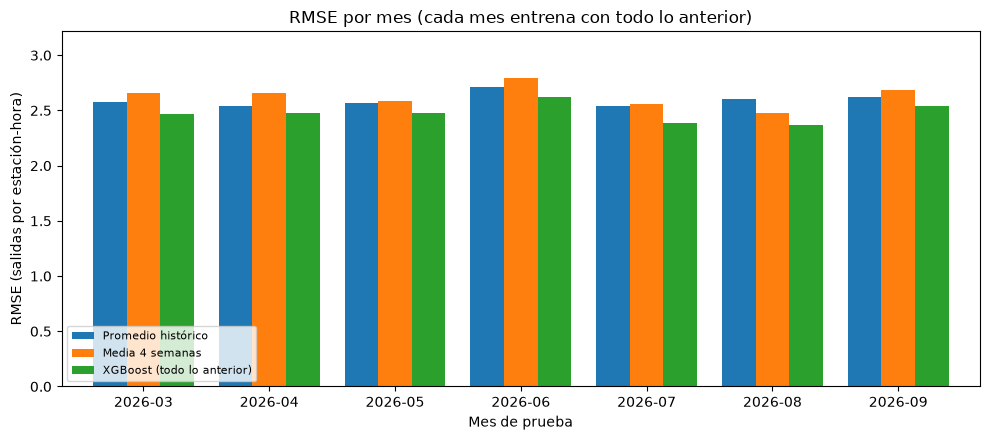

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
orden = [m for m in ["Promedio histórico", "Media 4 semanas", "XGBoost (todo lo anterior)", "XGBoost (últimos 6 meses)"]
         if m in res["modelo"].unique()]
t = res.pivot(index="mes", columns="modelo", values="RMSE")[orden]
t.plot.bar(ax=ax, width=0.8, rot=0)
ax.set_ylabel("RMSE (salidas por estación-hora)")
ax.set_xlabel("Mes de prueba")
ax.set_title("RMSE por mes (cada mes entrena con todo lo anterior)")
ax.legend(fontsize=8, loc="lower left")
ax.set_ylim(0, t.max().max() * 1.15)
fig.tight_layout()
fig.savefig("../figures/17_rmse_por_mes.png", dpi=150)
plt.show()

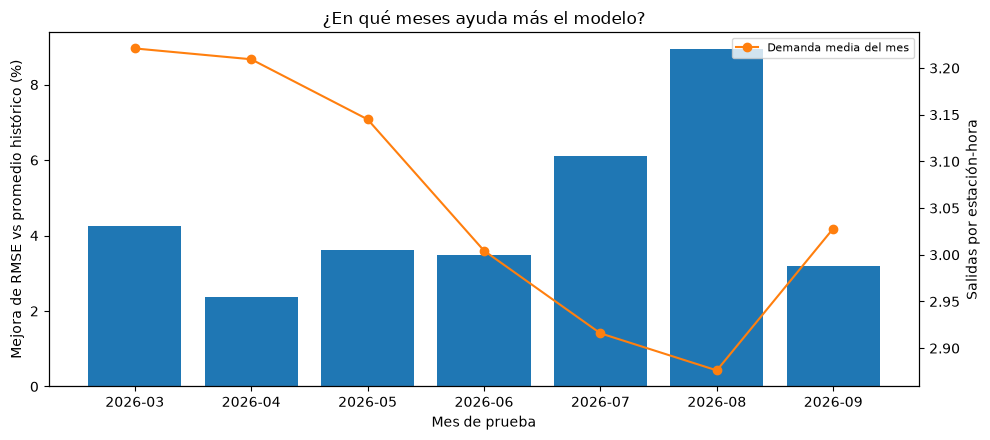

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
m = mejora.drop(columns="Promedio").loc["XGBoost (todo lo anterior)"]
ax.bar(m.index, m.values, color="C0")
ax.set_ylabel("Mejora de RMSE vs promedio histórico (%)")
ax.set_xlabel("Mes de prueba")
ax.axhline(0, color="gray", lw=0.8)
ax2 = ax.twinx()
ax2.plot(dem.index, dem["demanda_prueba"], color="C1", marker="o", label="Demanda media del mes")
ax2.set_ylabel("Salidas por estación-hora")
ax2.set_ylim(0, dem["demanda_prueba"].max() * 1.15)   # eje desde 0: la caída de demanda es de ~10 %, no mayor
ax2.legend(loc="upper right", fontsize=8)
ax.set_title("¿En qué meses ayuda más el modelo?")
fig.tight_layout()
fig.savefig("../figures/18_mejora_por_mes.png", dpi=150)
plt.show()

## Lectura de resultados

- **Estable.** XGBoost tiene el menor RMSE y MAE en los 7 meses (mar–sep 2026). El RMSE promedio es 2.475 contra 2.594 del promedio histórico; el modelo se mueve poco (2.37 a 2.62).
- **Mejora modesta pero constante:** de 2.4 % (abril) a 8.9 % (agosto) sobre el promedio histórico, 4.6 % en promedio.
- **Ayuda más cuando la demanda se aleja del nivel de entrenamiento.** En julio y agosto la demanda baja a ~2.9 salidas por estación-hora (el entrenamiento promedia ~3.15). El promedio histórico se queda en el nivel viejo y sobrepredice (sesgo +0.27 y +0.20); XGBoost se ajusta con `media_4sem` y `nivel_semana` (sesgo +0.11 y +0.07).
- **Junio es el mes más difícil.** Todos los modelos sobrepredicen (sesgo de +0.19 a +0.23). Una hipótesis es el Mundial (inauguración el 11 de junio en CDMX) junto con el inicio de lluvias; **no está comprobada**, habría que revisar la demanda por día. Es un ejemplo de lo que el modelo no puede ver.
- **La media de 4 semanas** pierde contra el promedio histórico en 6 de 7 meses (solo gana en agosto), así que la mejora del modelo no se reduce a "mirar lo reciente".
- **Septiembre 2026** es un mes que ningún notebook anterior había visto, y la mejora se mantiene (3.2 %).
- **Limitaciones.** (1) Los hiperparámetros se eligieron en `02_modelo.ipynb` con datos de junio–julio de 2026, así que para los meses de prueba de marzo a junio se eligieron con datos posteriores; el efecto es pequeño porque son fijos y los árboles se eligen dentro de cada train. (2) `COMPARAR_6M` quedó en `False`: la comparación con menos historia está en los notebooks 04 y 05.